In [1]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import yaml
from pathlib import Path
from copy import deepcopy
from scipy.optimize import least_squares

from models.aux_funcs_00 import *

ROOT = Path.cwd()

In [2]:
# Controls

OUTPUT_DIR = ROOT / "results/sample3/"

FG075_WEIGHT = 5.0

BASE_SEED = 1

Nruns = 50

FMSURF = 2500

run_opt = True

THRESHOLD_SSE = 1e2#  0.12

In [3]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Inputs
with open("inputs/sample3_inputs.yaml", "r") as f:
    inputs = yaml.safe_load(f)
with open("inputs/sample3_experimentalData.yaml", "r") as f:
    experiments = yaml.safe_load(f)

In [5]:
inputs

{'core': {'k': 4.0384901436e-13, 'phi': 0.099, 'L': 0.245, 'D': 0.0381},
 'relPerm': {'swc': 0.36,
  'sgr': 0.0,
  'sor': 0.16,
  'nw_': 2.7,
  'ng_': 6.89,
  'no_': 3.0,
  'krw0': 0.365,
  'krg0': 0.278,
  'kro0': 0.574},
 'fluids': {'muw': 0.000603, 'mug': 1.25e-05, 'muo': 0.005, 'sigma': 1.0}}

In [6]:
fixed_rp = np.array([
    inputs["relPerm"][key]
    for key in ("nw_", "ng_", "krw0", "krg0", "swc", "sgr", "sor")
], dtype=float)
fixed_rp

array([2.7  , 6.89 , 0.365, 0.278, 0.36 , 0.   , 0.16 ])

In [7]:
# Reading models
rp_module = load_module("relpermModel", "models/relativePermeabilityModels.py")
foam_module = load_module("foamModel", "models/foamModels.py")
foam_module.coreyBrooks3ph = rp_module.coreyBrooks3ph(inputs["relPerm"])


In [8]:
# Reading experiments
CONCENTRATIONS = (625, 1250, 2500)

# DIFFERENT SURFACTANT CONCENTRATIONS

scans = {}
velocity_by_concentration = {}
frames = []
for concentration in CONCENTRATIONS:
    experiment = experiments[f"FQS_{concentration}mgL"]
    scan_all = np.array(experiment["data"], dtype=float)
    scans[concentration] = scan_all

    velocity = float(experiment["ut"]) * 0.3048 / 86400 # convert to m/s
    velocity_by_concentration[concentration] = velocity
    frames.append(pd.DataFrame({
        "experiment": f"{concentration} mg/L", "Cs_mg_L": concentration,
        "fg": scan_all[:, 0], "muApp_cP": scan_all[:, 1], "ut": velocity,
    }))
surf_observations = pd.concat(frames, ignore_index=True)

# separating data
fg_obs = surf_observations["fg"].to_numpy()
mu_obs = surf_observations["muApp_cP"].to_numpy()
cs_obs = surf_observations["Cs_mg_L"].to_numpy(dtype=float)
ut_obs = surf_observations["ut"].to_numpy()
is_foam = np.ones(len(fg_obs), dtype=bool)
so_viscosity_obs = np.zeros_like(fg_obs, dtype=float)
surf_observations["So"] = so_viscosity_obs

# OIL OBSERVATION (foil)
oil_observations = pd.DataFrame(
    experiments["oil_observations"]["data"],
    columns=["So", "F2"]
)
so_obs = oil_observations["So"].to_numpy(dtype=float)
f2_obs = oil_observations["F2"].to_numpy(dtype=float)

# wheights and scale
point_weights = np.where(np.isclose(fg_obs, 0.75), FG075_WEIGHT, 1.0)
mu_scale, f2_scale = float(mu_obs.max()), float(f2_obs.max())

ValueError: 2 columns passed, passed data had 3 columns

In [ ]:
display(surf_observations)
display(oil_observations)
print(f"mu scale: {mu_scale:.2f}, f2 scale: {f2_scale:.2f}")

,experiment,Cs_mg_L,fg,muApp_cP,ut,So
0,625 mg/L,625,0.25,50.42,0.000007,0.0
1,625 mg/L,625,0.50,164.64,0.000007,0.0
2,625 mg/L,625,0.70,253.69,0.000007,0.0
3,625 mg/L,625,0.75,267.24,0.000007,0.0
4,625 mg/L,625,0.85,214.97,0.000007,0.0
5,625 mg/L,625,0.90,193.68,0.000007,0.0
6,625 mg/L,625,1.00,48.49,0.000007,0.0
7,1250 mg/L,1250,0.25,414.36,0.000007,0.0
8,1250 mg/L,1250,0.50,789.92,0.000007,0.0
9,1250 mg/L,1250,0.70,1012.54,0.000007,0.0


,So,F2
0,0.0667,1.0000
1,0.2191,0.8904
2,0.2724,0.5469
3,0.3115,0.3530
4,0.3541,0.1749


mu scale: 2079.19, f2 scale: 1.00


## Função objetivo

$$\chi^2(\theta)=\alpha_{surf}\sum_k w_k\left[\frac{\mu_k^{exp}-\mu_k(\theta;S_o=0)}{\max_j\mu_j^{exp}}\right]^2+\alpha_{oil}\sum_i\left[\frac{F_{2,i}^{exp}-F_{oil}(S_{o,i};\theta)}{\max_j F_{2,j}^{exp}}\right]^2.$$

Onde:
Nos scans sem óleo, o fluxo fracionário de gás é resolvido para Sw e a viscosidade é calculada com STARS/Corey:

$$\lambda_w=k_{rw}/\mu_w,\quad \lambda_g^{foam}=\frac{k_{rg}/\mu_g}{1+fmmob\,F_{dry}\,F_{surf}\,F_{oil}(0)},\quad f_g=\frac{\lambda_g^{foam}}{\lambda_w+\lambda_g^{foam}},\quad \mu_{app}=\frac{1}{\lambda_w+\lambda_g^{foam}}.$$

$$F_{dry}=\frac12+\frac{\arctan[epdry(S_w-fmdry)]}{\pi},\qquad F_{surf}(C_s)=\begin{cases}(C_s/fmsurf)^{epsurf},&C_s<fmsurf,\\1,&C_s\geq fmsurf.\end{cases}$$

E para observações com óleo:
$$F_{oil}(S_o)=\begin{cases}1,&S_o<floil,\\((fmoil-S_o)/(fmoil-floil))^{epoil},&floil\leq S_o\leq fmoil,\\0,&S_o>fmoil.\end{cases}$$

In [ ]:
# Fitting bounds
SAT_EPS = 1e-6

bounds = {
    "fmmob": (10, 1e7),
    "epdry": (10, 1e4),
    "fmdry": (inputs["relPerm"]["swc"], 1 - inputs["relPerm"]["swc"]),
    "epsurf": (1e-3, 10),
    "epoil": (1e-3, 10),
    "fmoil": (0, 1-SAT_EPS),
    "floil": (SAT_EPS, 1)
}
names = list(bounds.keys())
print(names)

lower_bounds = np.array([b[0] for b in bounds.values()])
upper_bounds = np.array([b[1] for b in bounds.values()])

# Os quatro parâmetros de espuma do bloco de surfactante usam coordenadas
# logarítmicas. 
# Óleo usa `(log(epoil), floil, qoil)` com `fmoil=floil+(1-floil)*qoil`,
# impondo `epoil>0` e `0<=floil<fmoil<=1`.
zlo = np.r_[np.log(lower_bounds[:5]),lower_bounds[5:]]
zhi = np.r_[np.log(upper_bounds[:5]),upper_bounds[5:]]

internal_names = [f"log({name})" for name in ["fmmob", "epdry", "fmdry", "epsurf"]]+["log(epoil)", "floil", "qoil"]
internal_names


['fmmob', 'epdry', 'fmdry', 'epsurf', 'epoil', 'fmoil', 'floil']


['log(fmmob)',
 'log(epdry)',
 'log(fmdry)',
 'log(epsurf)',
 'log(epoil)',
 'floil',
 'qoil']

In [ ]:
# Running the optimization
if run_opt:
    seeds = np.arange(BASE_SEED, BASE_SEED + Nruns) 
    parameter_rows, initial_rows, diagnostic_rows = [], [], []
    best, best_seed, best_sse = None, None, np.inf

    initial_reference = np.array([2005.5, 1000., 0.5, 1.0, 1., .5, .05])
    start_margin = np.minimum(1e-6, .1*(zhi-zlo))
    initial_z = np.clip(encode(initial_reference, internal_names), zlo+start_margin, zhi-start_margin)


    for run, seed in enumerate(tqdm(seeds, desc="Optimization runs")):
        z0 = make_initial(int(seed), initial_z, zlo, zhi, start_margin, so_obs, f2_obs, SAT_EPS)
        initial_rows.append(decode(z0))
        fitted = np.full(len(names), np.nan)
        diagnostic = dict(seed=int(seed), success=False, surf_SSE=np.nan, oil_SSE=np.nan,
                            weighted_normalized_SSE=np.nan, status=-99, nfev=0, optimality=np.nan, message="")

        try:
            fit = least_squares(residual, z0, args=(foam_module, point_weights, mu_obs, f2_obs, so_obs, mu_scale, f2_scale, fg_obs, is_foam, ut_obs, cs_obs, fixed_rp, FMSURF, inputs),
                                bounds=(zlo, zhi), max_nfev=3000,
                                ftol=1e-10, xtol=1e-10, gtol=1e-9, x_scale="jac",
                                method="trf")
            fitted = decode(fit.x)
            components = objective_components(fitted, foam_module, point_weights, mu_obs, f2_obs, so_obs, mu_scale, f2_scale, fg_obs, is_foam, ut_obs, cs_obs, fixed_rp, FMSURF, inputs)
            diagnostic.update(components, success=bool(fit.success), status=int(fit.status), nfev=int(fit.nfev), optimality=float(fit.optimality), message=str(fit.message))
            if fit.success and np.isfinite(fitted).all() and components["weighted_normalized_SSE"] < best_sse:
                        best, best_seed, best_sse = fit, int(seed), components["weighted_normalized_SSE"]

        except (ValueError, FloatingPointError, RuntimeError) as exc:
            diagnostic["message"] = f"{type(exc).__name__}: {exc}"
            print(diagnostic["message"])

        parameter_rows.append(fitted)
        diagnostic_rows.append(diagnostic)

    # Saving results
    params_df = pd.DataFrame(parameter_rows, columns=names, index=pd.Index(seeds, name="seed"))
    initial_params_df = pd.DataFrame(initial_rows, columns=names, index=params_df.index)
    diagnostics_df = pd.DataFrame(diagnostic_rows).set_index("seed")

    for filename, table in {
        "experimental_parameters": params_df,
        "experimental_initial_parameters": initial_params_df,
        "experimental_diagnostics": diagnostics_df,
    }.items():
        table.to_csv(OUTPUT_DIR / f"{filename}.csv")

else:
    # Load previous results
    params_df = pd.read_csv(OUTPUT_DIR / "experimental_parameters.csv", index_col="seed")
    initial_params_df = pd.read_csv(OUTPUT_DIR / "experimental_initial_parameters.csv", index_col="seed")
    diagnostics_df = pd.read_csv(OUTPUT_DIR / "experimental_diagnostics.csv", index_col="seed")

diagnostics_df.head()


Optimization runs:   0%|          | 0/2000 [00:00<?, ?it/s]

,success,surf_SSE,oil_SSE,weighted_normalized_SSE,status,nfev,optimality,message
seed,,,,,,,,
1,True,0.109298,0.000035,0.109334,2,24,5.389066e-07,`ftol` termination condition is satisfied.
2,True,0.109298,0.000035,0.109334,2,24,2.200046e-07,`ftol` termination condition is satisfied.
3,True,0.109298,0.000035,0.109334,2,19,1.372619e-06,`ftol` termination condition is satisfied.
4,True,0.109298,0.000035,0.109334,2,15,1.081621e-07,`ftol` termination condition is satisfied.
5,True,0.109298,0.000035,0.109334,2,23,4.178884e-08,`ftol` termination condition is satisfied.


In [ ]:
# select runs which values < threshold_sse

values = diagnostics_df["weighted_normalized_SSE"]

select = diagnostics_df["success"].fillna(False).astype(bool) & np.isfinite(values) & (values < THRESHOLD_SSE)

parameter_statistics = diagnostics_df[["surf_SSE", "oil_SSE", "weighted_normalized_SSE"]].describe(percentiles=[.25, .5, .75]).T.rename(
    columns={"25%": "q25", "50%": "median", "75%": "q75"})
display(parameter_statistics)

,count,mean,std,min,q25,median,q75,max
surf_SSE,2000.0,0.109298,2.035446e-10,0.109298,0.109298,0.109298,0.109298,0.109298
oil_SSE,2000.0,0.126467,4.083483e-01,0.000035,0.000035,0.000035,0.000035,2.247111
weighted_normalized_SSE,2000.0,0.235765,4.083483e-01,0.109334,0.109334,0.109334,0.109334,2.356409


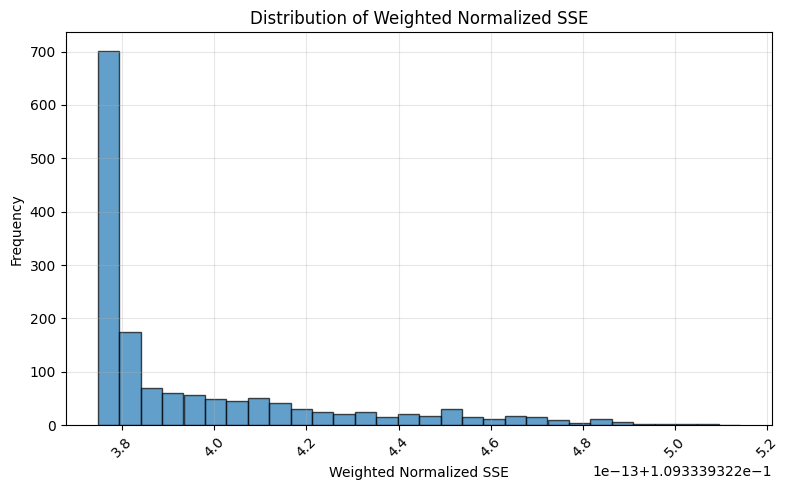

In [ ]:
from matplotlib.ticker import MultipleLocator

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    diagnostics_df["weighted_normalized_SSE"].loc[select],
    bins=30,
    edgecolor="black",
    alpha=0.7
)

ax.set_xlabel("Weighted Normalized SSE")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Weighted Normalized SSE")
ax.tick_params(axis="x", labelrotation=45)
ax.grid(alpha=0.3)
# ax.xaxis.set_major_locator(MultipleLocator(0.1))

plt.tight_layout()
plt.show()

In [ ]:
params_df.head()

parameter_statistics = params_df[select].describe(percentiles=[.25, .5, .75]).T.rename(
    columns={"25%": "q25", "50%": "median", "75%": "q75"})
display(parameter_statistics)


,count,mean,std,min,q25,median,q75,max
fmmob,1539.0,59792.947010,5.402794e-03,59792.925244,59792.944134,59792.948582,59792.950180,59792.966773
epdry,1539.0,106.628249,3.668314e-05,106.628099,106.628236,106.628248,106.628269,106.628349
fmdry,1539.0,0.377730,2.570901e-09,0.377730,0.377730,0.377730,0.377730,0.377730
epsurf,1539.0,1.551062,8.772673e-08,1.551061,1.551062,1.551062,1.551062,1.551062
epoil,1539.0,1.803404,3.666157e-07,1.803403,1.803404,1.803404,1.803404,1.803406
fmoil,1539.0,0.447157,3.205823e-08,0.447157,0.447157,0.447157,0.447157,0.447157
floil,1539.0,0.203814,1.829941e-09,0.203814,0.203814,0.203814,0.203814,0.203814


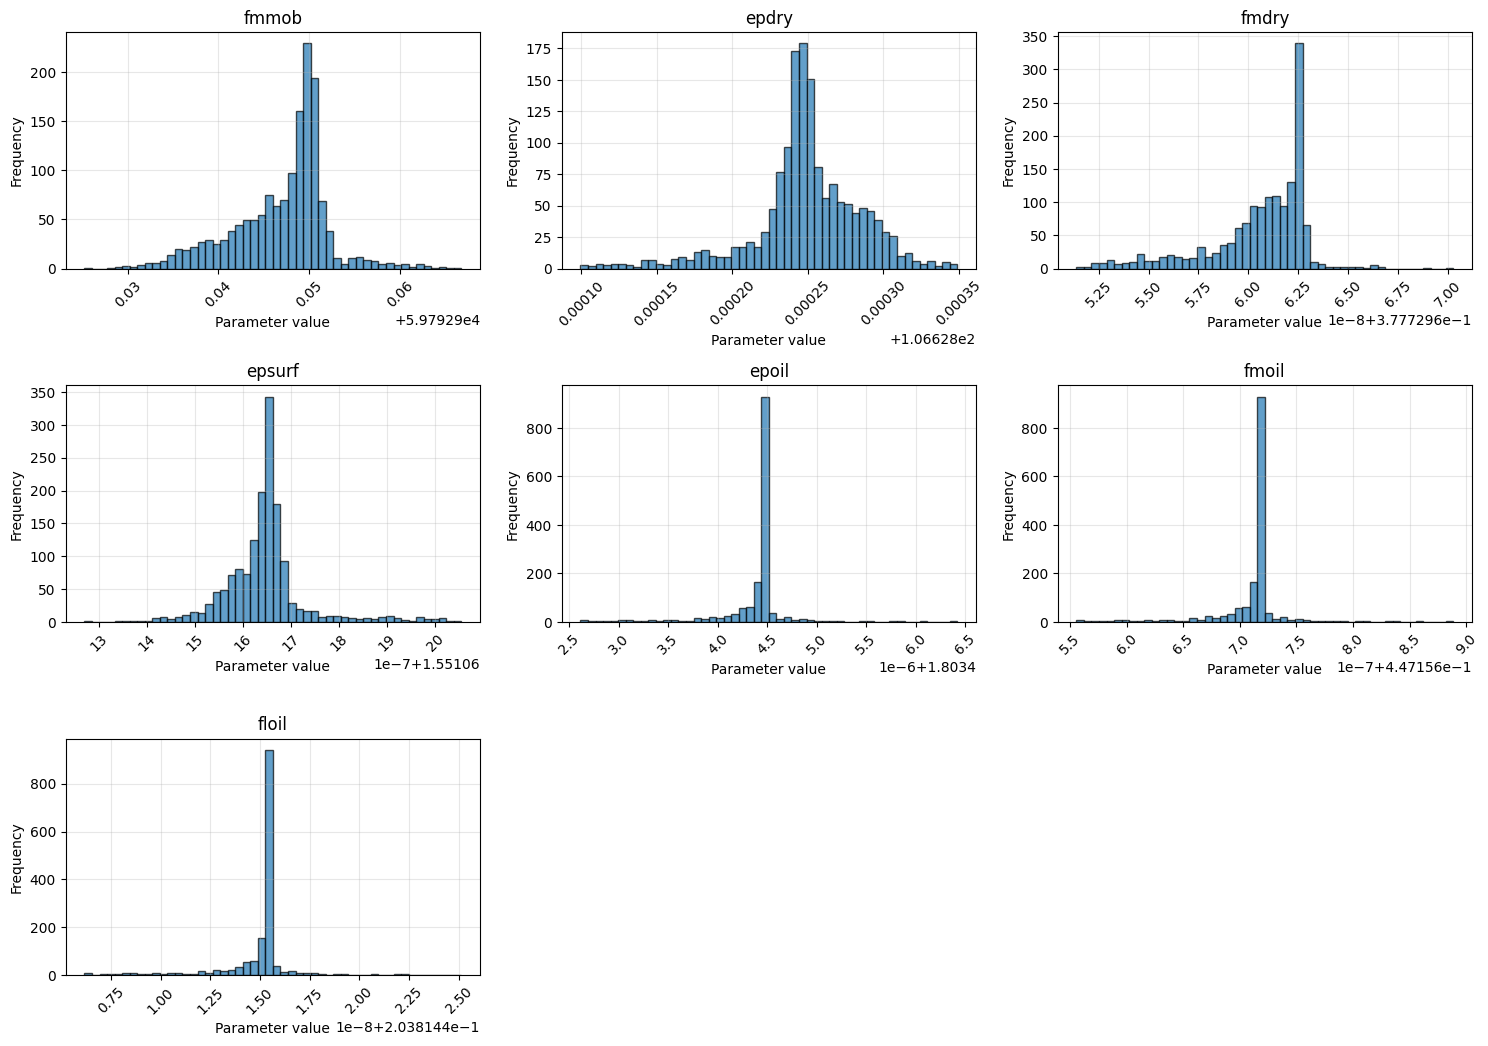

In [ ]:
# Filter selected rows
params_selected = params_df.loc[select]

ncols = 3
nrows = int(np.ceil(len(params_selected.columns) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = np.ravel(axes)

for ax, col in zip(axes, params_selected.columns):
    ax.hist(params_selected[col], bins=50, edgecolor="black", alpha=0.7)
    ax.set_title(col)
    ax.set_xlabel("Parameter value")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", labelrotation=45)

# Remove unused subplots
for ax in axes[len(params_selected.columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

/tmp/ipykernel_17030/2564640980.py:109: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()


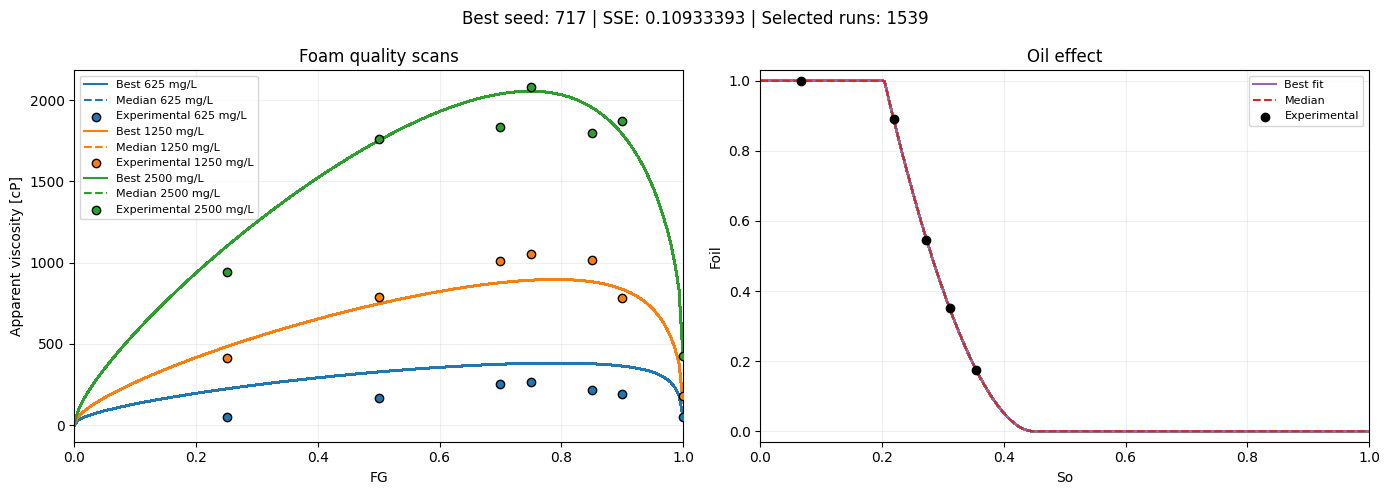

In [ ]:
# Parâmetros físicos das rodadas selecionadas
params_selected = params_df.loc[select, names].copy()
params_selected = params_selected.loc[
    np.isfinite(params_selected).all(axis=1)
]

best_seed = diagnostics_df.loc[
    params_selected.index, "weighted_normalized_SSE"
].idxmin()

theta = params_selected.loc[best_seed].to_numpy(dtype=float)
median_theta = params_selected.median().to_numpy(dtype=float)

sw_grid = np.linspace(0, 1, 151)
oil_grid = np.linspace(0, 1, 501)


def scan(p, cs):
    return predict(
        p,
        sw_grid,
        np.ones(sw_grid.size, dtype=bool),
        np.full(sw_grid.size, velocity_by_concentration[cs]),
        np.full(sw_grid.size, cs, dtype=float),
        foam_module,
        fixed_rp,
        FMSURF,
        inputs,
    )[0]


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Selected runs
for _, row in params_selected.iterrows():
    p = row.to_numpy(dtype=float)

    for i, cs in enumerate(CONCENTRATIONS):
        axes[0].plot(
            sw_grid, scan(p, cs),
            color=f"C{i}", alpha=0.15, zorder=1,
        )

    axes[1].plot(
        oil_grid,
        predict_oil(p, foam_module, oil_grid),
        color="gray", alpha=0.15, zorder=1,
    )

# Best fit, median and experimental data
for i, cs in enumerate(CONCENTRATIONS):
    color = f"C{i}"

    axes[0].plot(
        sw_grid, scan(theta, cs),
        color=color, label=f"Best {cs} mg/L", zorder=2,
    )
    axes[0].plot(
        sw_grid, scan(median_theta, cs),
        color=color, ls="--", label=f"Median {cs} mg/L", zorder=2,
    )
    axes[0].scatter(
        scans[cs][:, 0], scans[cs][:, 1],
        color=color, edgecolor="black",
        label=f"Experimental {cs} mg/L", zorder=3,
    )

# Oil
axes[1].plot(
    oil_grid,
    predict_oil(theta, foam_module, oil_grid),
    color="tab:purple", label="Best fit", zorder=2,
)
axes[1].plot(
    oil_grid,
    predict_oil(median_theta, foam_module, oil_grid),
    color="tab:red", ls="--", label="Median", zorder=2,
)
axes[1].scatter(
    so_obs, f2_obs,
    color="black", label="Experimental", zorder=3,
)

# Formatting
axes[0].set(
    xlabel="FG",
    ylabel="Apparent viscosity [cP]",
    title="Foam quality scans",
    xlim=(0, 1),
)
axes[1].set(
    xlabel="So",
    ylabel="Foil",
    title="Oil effect",
    xlim=(0, 1),
    ylim=(-0.03, 1.03),
)

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

fig.suptitle(
    f"Best seed: {best_seed} | "
    f"SSE: {diagnostics_df.loc[best_seed, 'weighted_normalized_SSE']:.8g} | "
    f"Selected runs: {len(params_selected)}"
)

fig.tight_layout()
plt.show()

In [ ]:
print("PERMEABILIDADE RELATIVA")
for name, value in inputs["relPerm"].items():
    print(f"  {name:8s} = {value:.10g}")

foam_params = dict(zip(
    ("fmmob", "epdry", "fmdry", "epsurf", "epoil", "fmoil", "floil"),
    theta,
))
foam_params["fmsurf"] = FMSURF

print("\nESPUMA")
for name in (
    "fmmob", "fmdry", "epdry", "fmsurf",
    "epsurf", "epoil", "fmoil", "floil",
):
    print(f"  {name:8s} = {foam_params[name]:.10g}")

print("Foil_Act = True; Fsurf_Act = True; Fshear_Act = False")

PERMEABILIDADE RELATIVA
  swc      = 0.36
  sgr      = 0
  sor      = 0
  nw_      = 2.7
  ng_      = 6.89
  no_      = 1
  krw0     = 0.365
  krg0     = 0.278
  kro0     = 1

ESPUMA
  fmmob    = 59792.95018
  fmdry    = 0.3777296626
  epdry    = 106.6282429
  fmsurf   = 2500
  epsurf   = 1.551061654
  epoil    = 1.803404402
  fmoil    = 0.4471567121
  floil    = 0.2038144151
Foil_Act = True; Fsurf_Act = True; Fshear_Act = False
